# 03 — Sistema Especialista (regras SE-ENTÃO)

Este notebook constrói a **base de conhecimento** e o **motor de inferência**
do sistema especialista para os dois problemas:

* **Classificação** (`Diabetes_Risk`): quatro regras com resolução de conflito
  por prioridade.
* **Regressão** (`Diabetes_Risk_Score`): como o alvo é contínuo, uma base
  finita de regras não consegue enumerar todos os valores possíveis. A solução
  adotada é um **motor de pontuação aditiva**: cada regra representa uma faixa
  clinicamente interpretável e contribui com pontos para um escore.

As regras usam apenas o conjunto de treino e conhecimento de domínio. O teste é usado somente na avaliação final.

In [1]:
from pathlib import Path
import sys
import warnings

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import *
from src.prepare_data import preparar_classificacao, preparar_regressao
from src.expert_system import (
    aplicar_sistema_especialista,
    aplicar_sistema_especialista_pontuacao,
    inferir,
    inferir_pontuacao,
    resumo_regras,
)
from src.metrics import calcular_metricas_classificacao, calcular_metricas_regressao
from src.profiling import (
    medir_inferencia,
    medir_tamanho_serializado,
    medir_tamanho_arquivo,
    estimar_energia_co2,
)
from src.rules_io import (
    exportar_regras_txt,
    ler_cronometro,
    resumo_cronometro,
    sessoes_pendentes,
)

from rules.regras_classificacao import REGRAS_CLASSIFICACAO
from rules.regras_regressao import (
    REGRAS_REGRESSAO,
    REGRAS_REGRESSAO_V1,
    PONTUACAO_BASE,
    LIMITES_PONTUACAO,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
criar_diretorios()

print("Raiz do projeto:", ROOT_DIR)
print("Semente:", RANDOM_STATE)

Raiz do projeto: C:\Users\lucas\OneDrive\Documentos\avaliacao-comparativa-modelos-ia
Semente: 42


## 1. Protocolo experimental

A mesma divisão treino/teste (80/20, semente 42) será reutilizada por todos os
modelos. Na classificação a divisão é estratificada.

In [2]:
X_train_c, X_test_c, y_train_c, y_test_c = preparar_classificacao()
X_train_r, X_test_r, y_train_r, y_test_r = preparar_regressao()

resumo_dados = pd.DataFrame(
    {
        "Treino": [len(X_train_c), len(X_train_r)],
        "Teste": [len(X_test_c), len(X_test_r)],
        "Features": [X_train_c.shape[1], X_train_r.shape[1]],
    },
    index=["Classificação", "Regressão"],
)
display(resumo_dados)

distribuicao_classes = (
    y_train_c.value_counts(normalize=True)
    .reindex(CLASSES)
    .mul(100)
    .round(2)
    .rename("Treino (%)")
    .to_frame()
)
distribuicao_classes["Teste (%)"] = (
    y_test_c.value_counts(normalize=True).reindex(CLASSES).mul(100).round(2)
)
display(distribuicao_classes)

,Treino,Teste,Features
Classificação,40000,10000,9
Regressão,40000,10000,8


,Treino (%),Teste (%)
Diabetes_Risk,,
Low,0.94,0.94
Moderate,25.87,25.87
High,73.18,73.19


A classe **Low** é rara (menos de 1% dos registros). Isso já antecipa que a
acurácia isolada pode ser enganosa: um modelo que nunca prevê *Low* ainda
acertaria a maioria dos casos. Por isso o relatório também usa F1-score e
recall por classe.

## 2. Base de conhecimento — classificação

In [3]:
tabela_regras_c = resumo_regras(REGRAS_CLASSIFICACAO)
display(tabela_regras_c)

exportar_regras_txt(
    REGRAS_CLASSIFICACAO,
    RULES_DIR / "regras_classificacao.txt",
    "Base de conhecimento — Classificação (Diabetes_Risk)",
)

,Regra,Tipo,Condições,Descrição,Conclusão,Prioridade
0,R1,heuristica,Fasting_Blood_Sugar >= 126 E HbA1c >= 6.5,Risco alto — critérios diagnósticos de diabete...,High,1
1,R2,heuristica,"Fasting_Blood_Sugar entre (80, 125) E HbA1c en...",Risco moderado — faixa intermediária de glicem...,Moderate,2
2,R3,heuristica,Fasting_Blood_Sugar < 100 E HbA1c < 5.7,Risco baixo — glicemia e HbA1c abaixo dos limi...,Low,3
3,R4,heuristica,"Fasting_Blood_Sugar entre_aberto_direita (80, ...",Risco moderado — glicemia normal com HbA1c na ...,Moderate,4


WindowsPath('C:/Users/lucas/OneDrive/Documentos/avaliacao-comparativa-modelos-ia/rules/regras_classificacao.txt')

### 2.1 Inferência de um registro (motor simbólico)

O motor separa a base de conhecimento do mecanismo de inferência. Para um
registro, ele devolve a conclusão vencedora, todas as regras ativadas e se
houve conflito.

In [4]:
mascara_exemplo = (
    X_test_c["Fasting_Blood_Sugar"].ge(126)
    & X_test_c["HbA1c"].ge(6.5)
)
exemplo = X_test_c.loc[mascara_exemplo].iloc[0]
fatos = exemplo.to_dict()
resultado = inferir(fatos, REGRAS_CLASSIFICACAO)

print("Fatos do registro:")
display(pd.Series(fatos, name="Valor").to_frame())
print("\nResultado da inferência:")
display(pd.Series(resultado, name="Resultado").to_frame())

Fatos do registro:


,Valor
Fasting_Blood_Sugar,214.0
HbA1c,12.5
Age,84.0
BMI,26.1
Family_History_Diabetes,Yes
Hypertension,Yes
Diet_Quality,Healthy
PCOS,No
Heart_Disease,Yes



Resultado da inferência:


,Resultado
conclusao,High
regras_ativadas,[R1]
conclusoes_encontradas,[High]
houve_conflito,False
regra_selecionada,R1


### 2.2 Equivalência entre o motor simbólico e o vetorizado

O motor vetorizado (matriz de ativação) é usado para avaliar milhares de
registros com rapidez. O teste abaixo compara os dois caminhos em uma amostra
aleatória; qualquer divergência interrompe a execução.

In [5]:
amostra = X_test_c.sample(200, random_state=RANDOM_STATE)
resultados_vetor = aplicar_sistema_especialista(amostra, REGRAS_CLASSIFICACAO)

for indice, linha in amostra.iterrows():
    simbolico = inferir(linha.to_dict(), REGRAS_CLASSIFICACAO)
    vetor = resultados_vetor.loc[indice]
    assert simbolico["conclusao"] == vetor["conclusao"]
    assert simbolico["regra_selecionada"] == vetor["regra_selecionada"]
    assert simbolico["regras_ativadas"] == vetor["regras_ativadas"]

print("Motor simbólico e vetorizado produzem o mesmo resultado em 200 registros.")

Motor simbólico e vetorizado produzem o mesmo resultado em 200 registros.


### 2.3 Avaliação no conjunto de teste

O sistema é aplicado a todos os registros. Quando nenhuma regra é ativada, a
conclusão é `Indeterminado`; esses casos ficam fora das métricas de acurácia
(mas a cobertura é reportada, pois um sistema que classifica pouco não é útil
na prática).

In [6]:
resultado_teste_c = aplicar_sistema_especialista(X_test_c, REGRAS_CLASSIFICACAO)
resultado_treino_c = aplicar_sistema_especialista(X_train_c, REGRAS_CLASSIFICACAO)

cobertura = resultado_teste_c["conclusao"].ne("Indeterminado").mean()
conflitos = int(resultado_teste_c["houve_conflito"].sum())

print(f"Cobertura no teste: {cobertura:.2%}")
print(f"Registros com conflito de regras: {conflitos}")
display(
    resultado_teste_c["conclusao"]
    .value_counts(dropna=False)
    .rename_axis("Conclusão")
    .to_frame("Quantidade")
)
display(
    resultado_teste_c["regra_selecionada"]
    .value_counts(dropna=False)
    .rename_axis("Regra selecionada")
    .to_frame("Quantidade")
)

Cobertura no teste: 53.87%
Registros com conflito de regras: 45


,Quantidade
Conclusão,
Indeterminado,4613
High,4607
Moderate,495
Low,285


,Quantidade
Regra selecionada,
None,4613
R1,4607
R2,441
R3,285
R4,54


,Teste
Accuracy,0.8766
Precision (Macro),0.5760
Recall (Macro),0.6789
F1-Score (Macro),0.5618
Precision (Weighted),0.8936
Recall (Weighted),0.8766
F1-Score (Weighted),0.8794
Precision (High),0.9477
Recall (High),0.9602
F1-Score (High),0.9539


Previsto,Low,Moderate,High
Real,,,
Low,41,20,0
Moderate,223,315,241
High,21,160,4366


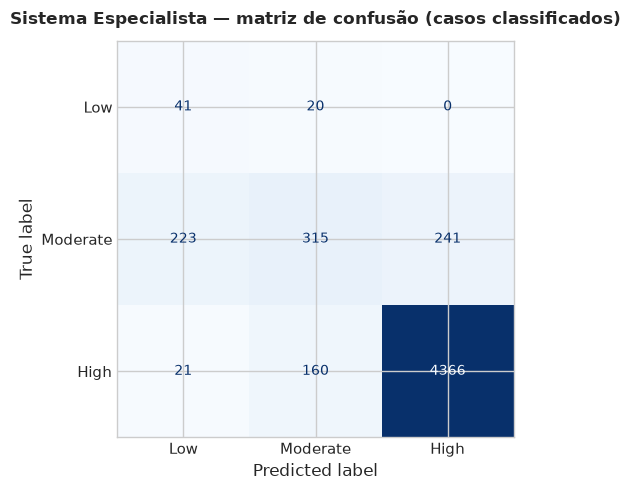

In [7]:
mascara = resultado_teste_c["conclusao"].ne("Indeterminado")

metricas_c_teste = calcular_metricas_classificacao(
    y_test_c[mascara],
    resultado_teste_c.loc[mascara, "conclusao"],
    classes=CLASSES,
    classe_positiva=CLASSE_POSITIVA,
)
display(pd.Series(metricas_c_teste, name="Teste").to_frame().round(4))

from src.metrics import matriz_confusao_ordenada
from src.visualization import plotar_matriz_confusao

cm = matriz_confusao_ordenada(
    y_test_c[mascara], resultado_teste_c.loc[mascara, "conclusao"], CLASSES
)
display(cm)

plotar_matriz_confusao(
    y_test_c[mascara],
    resultado_teste_c.loc[mascara, "conclusao"],
    classes=CLASSES,
    titulo="Sistema Especialista — matriz de confusão (casos classificados)",
    arquivo_saida=FIGURES_DIR / "matriz_confusao_especialista.png",
)
plt.show()

pd.Series(metricas_c_teste, name="Sistema Especialista").to_frame().to_csv(
    TABLES_DIR / "desempenho_especialista_classificacao.csv",
    encoding="utf-8",
)

### 3.1 Linha de base (v1): quatro células por medianas

In [8]:
resultado_treino_v1 = aplicar_sistema_especialista(X_train_r, REGRAS_REGRESSAO_V1)
resultado_teste_v1 = aplicar_sistema_especialista(X_test_r, REGRAS_REGRESSAO_V1)

pred_treino_v1 = resultado_treino_v1["conclusao"].astype(float)
pred_teste_v1 = resultado_teste_v1["conclusao"].astype(float)

metricas_v1_treino = calcular_metricas_regressao(y_train_r, pred_treino_v1)
metricas_v1_teste = calcular_metricas_regressao(y_test_r, pred_teste_v1)
display(pd.DataFrame({"Treino": metricas_v1_treino, "Teste": metricas_v1_teste}).round(4))

,Treino,Teste
MAE,11.2458,11.2721
MSE,193.6878,194.0894
RMSE,13.9172,13.9316
MAPE (%),17.1917,17.1501
R2,0.2054,0.1964
MedAE,9.6733,9.6733


A v1 só consegue produzir quatro valores distintos. Isso limita o R² mesmo que
as médias de cada célula estejam corretas: o modelo não distingue, por exemplo,
um paciente com glicemia 110 de outro com 180, pois ambos caem na mesma célula.

### 3.2 Base v2: regras de faixa com pontuação

In [9]:
tabela_regras_r = resumo_regras(REGRAS_REGRESSAO)
display(tabela_regras_r)

print(f"Pontuação base: {PONTUACAO_BASE} | Limites: {LIMITES_PONTUACAO}")
print(f"Total de regras de faixa: {len(REGRAS_REGRESSAO)}")

,Regra,Tipo,Condições,Descrição,Pontos
0,RG_G_BAIXA,heuristica,Fasting_Blood_Sugar < 100,Glicemia de jejum normal (< 100 mg/dL),-10
1,RG_G_PRE,heuristica,"Fasting_Blood_Sugar entre_aberto_direita (100,...",Glicemia de jejum na faixa de pré-diabetes (10...,0
2,RG_G_ALTA,heuristica,Fasting_Blood_Sugar >= 126,Glicemia de jejum em faixa diagnóstica (>= 126...,10
3,RG_H_BAIXA,heuristica,HbA1c < 5.7,"HbA1c normal (< 5,7%)",-9
4,RG_H_PRE,heuristica,"HbA1c entre_aberto_direita (5.7, 6.5)","HbA1c na faixa de pré-diabetes (5,7–6,4%)",0
5,RG_H_ALTA,heuristica,HbA1c >= 6.5,"HbA1c em faixa diagnóstica (>= 6,5%)",9
6,RG_IMC_BAIXO,heuristica,BMI < 25,IMC abaixo de 25 kg/m²,-5
7,RG_IMC_SOBREPESO,heuristica,"BMI entre_aberto_direita (25, 30)","IMC de sobrepeso (25–29,9 kg/m²)",-2
8,RG_IMC_OBESO1,heuristica,"BMI entre_aberto_direita (30, 35)","Obesidade grau I (30–34,9 kg/m²)",2
9,RG_IMC_OBESO2,heuristica,BMI >= 35,Obesidade grau II ou superior (>= 35 kg/m²),5


Pontuação base: 53 | Limites: (0.0, 100.0)
Total de regras de faixa: 19


### 3.3 Calibração dos pesos com o conjunto de treino

Os pesos não foram escolhidos no teste. Para cada variável numérica, uma faixa
de referência foi omitida (glicemia 100–125, HbA1c 5,7–6,5, IMC < 25, idade
40–54) e as demais faixas entraram como indicadores binários em uma regressão
linear (OLS) sobre o **treino**. O intercepto absorve a pontuação base e as
faixas de referência. Depois os coeficientes foram arredondados para inteiros,
gerando pontos fáceis de auditar.

In [10]:
def indicadores_calibracao(df: pd.DataFrame) -> pd.DataFrame:
    """Indicadores das faixas, omitindo a categoria de referência."""
    return pd.DataFrame(
        {
            "Glicemia < 100": (df["Fasting_Blood_Sugar"] < 100).astype(float),
            "Glicemia >= 126": (df["Fasting_Blood_Sugar"] >= 126).astype(float),
            "HbA1c < 5,7": (df["HbA1c"] < 5.7).astype(float),
            "HbA1c >= 6,5": (df["HbA1c"] >= 6.5).astype(float),
            "IMC 25-30": ((df["BMI"] >= 25) & (df["BMI"] < 30)).astype(float),
            "IMC 30-35": ((df["BMI"] >= 30) & (df["BMI"] < 35)).astype(float),
            "IMC >= 35": (df["BMI"] >= 35).astype(float),
            "Idade < 40": (df["Age"] < 40).astype(float),
            "Idade 55-70": ((df["Age"] >= 55) & (df["Age"] < 70)).astype(float),
            "Idade >= 70": (df["Age"] >= 70).astype(float),
            "Histórico familiar": (df["Family_History_Diabetes"] == "Yes").astype(float),
            "Hipertensão": (df["Hypertension"] == "Yes").astype(float),
            "Dieta ruim": (df["Diet_Quality"] == "Poor").astype(float),
            "Atividade baixa": (df["Physical_Activity_Level"] == "Low").astype(float),
            "Atividade não informada": (
                df["Physical_Activity_Level"] == "Não_informado"
            ).astype(float),
        },
        index=df.index,
    )

X_calibracao = indicadores_calibracao(X_train_r)
desenho = np.column_stack([np.ones(len(X_calibracao)), X_calibracao.to_numpy()])
coeficientes, *_ = np.linalg.lstsq(desenho, y_train_r.to_numpy(), rcond=None)

calibracao = pd.DataFrame(
    {"Coeficiente OLS": coeficientes[1:]},
    index=X_calibracao.columns,
)
calibracao["Ponto final da regra"] = pd.Series(
    {
        "Glicemia < 100": -10,
        "Glicemia >= 126": 10,
        "HbA1c < 5,7": -9,
        "HbA1c >= 6,5": 9,
        "IMC 25-30": -2,
        "IMC 30-35": 2,
        "IMC >= 35": 5,
        "Idade < 40": -6,
        "Idade 55-70": 3,
        "Idade >= 70": 4,
        "Histórico familiar": 10,
        "Hipertensão": 6,
        "Dieta ruim": 6,
        "Atividade baixa": 6,
        "Atividade não informada": 2,
    }
)
calibracao["Diferença (regra - OLS)"] = (
    calibracao["Ponto final da regra"] - calibracao["Coeficiente OLS"]
)
display(calibracao.round(3))

r2_treino_ols = 1 - ((y_train_r - desenho @ coeficientes) ** 2).sum() / (
    (y_train_r - y_train_r.mean()) ** 2
).sum()
print(f"Intercepto OLS: {coeficientes[0]:.3f} (≈ pontuação base + faixas de referência)")
print(f"R² do modelo linear de calibração no treino: {r2_treino_ols:.4f}")

,Coeficiente OLS,Ponto final da regra,Diferença (regra - OLS)
Glicemia < 100,-9.953,-10,-0.047
Glicemia >= 126,9.676,10,0.324
"HbA1c < 5,7",-8.049,-9,-0.951
"HbA1c >= 6,5",9.499,9,-0.499
IMC 25-30,2.854,-2,-4.854
IMC 30-35,6.618,2,-4.618
IMC >= 35,9.329,5,-4.329
Idade < 40,-4.368,-6,-1.632
Idade 55-70,4.250,3,-1.250
Idade >= 70,5.777,4,-1.777


Intercepto OLS: 46.921 (≈ pontuação base + faixas de referência)
R² do modelo linear de calibração no treino: 0.7666


O intercepto (≈ 47) corresponde à pontuação base 53 já corrigida pela faixa de
IMC < 25 (−5) e idade 40–54 (−1): 53 − 5 − 1 = 47. Os coeficientes das faixas
são próximos dos pontos inteiros usados nas regras; as pequenas diferenças
(±1) vêm do arredondamento e de ajustes para manter a base legível. O R² do
modelo linear de calibração (0,767) é praticamente igual ao da base arredondada
(0,767), portanto a perda de precisão é desprezível.

Essa é a justificativa técnica para usar um motor aditivo: ele aproxima uma
função contínua por uma soma de efeitos interpretáveis, em vez de tentar
enumerar valores.

### 3.4 Avaliação da v2 e comparação com a v1

In [11]:
resultado_treino_v2 = aplicar_sistema_especialista_pontuacao(
    X_train_r, REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
)
resultado_teste_v2 = aplicar_sistema_especialista_pontuacao(
    X_test_r, REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
)

pred_treino_v2 = resultado_treino_v2["conclusao"].to_numpy()
pred_teste_v2 = resultado_teste_v2["conclusao"].to_numpy()

metricas_v2_treino = calcular_metricas_regressao(y_train_r, pred_treino_v2)
metricas_v2_teste = calcular_metricas_regressao(y_test_r, pred_teste_v2)

comparacao = pd.DataFrame(
    {
        "v1 (4 células) — Treino": metricas_v1_treino,
        "v1 (4 células) — Teste": metricas_v1_teste,
        "v2 (19 faixas) — Treino": metricas_v2_treino,
        "v2 (19 faixas) — Teste": metricas_v2_teste,
    }
)
display(comparacao.round(4))
comparacao.to_csv(TABLES_DIR / "comparacao_regras_regressao.csv", encoding="utf-8")

print("Regras ativadas por amostra (v2, teste):")
display(resultado_teste_v2["n_regras_ativadas"].value_counts().sort_index().to_frame("Amostras"))

,v1 (4 células) — Treino,v1 (4 células) — Teste,v2 (19 faixas) — Treino,v2 (19 faixas) — Teste
MAE,11.2458,11.2721,5.9902,5.9941
MSE,193.6878,194.0894,56.8542,56.6337
RMSE,13.9172,13.9316,7.5402,7.5255
MAPE (%),17.1917,17.1501,8.7760,8.7747
R2,0.2054,0.1964,0.7667,0.7655
MedAE,9.6733,9.6733,5.0000,5.0000


Regras ativadas por amostra (v2, teste):


,Amostras
n_regras_ativadas,
4,1109
5,3247
6,3647
7,1757
8,240


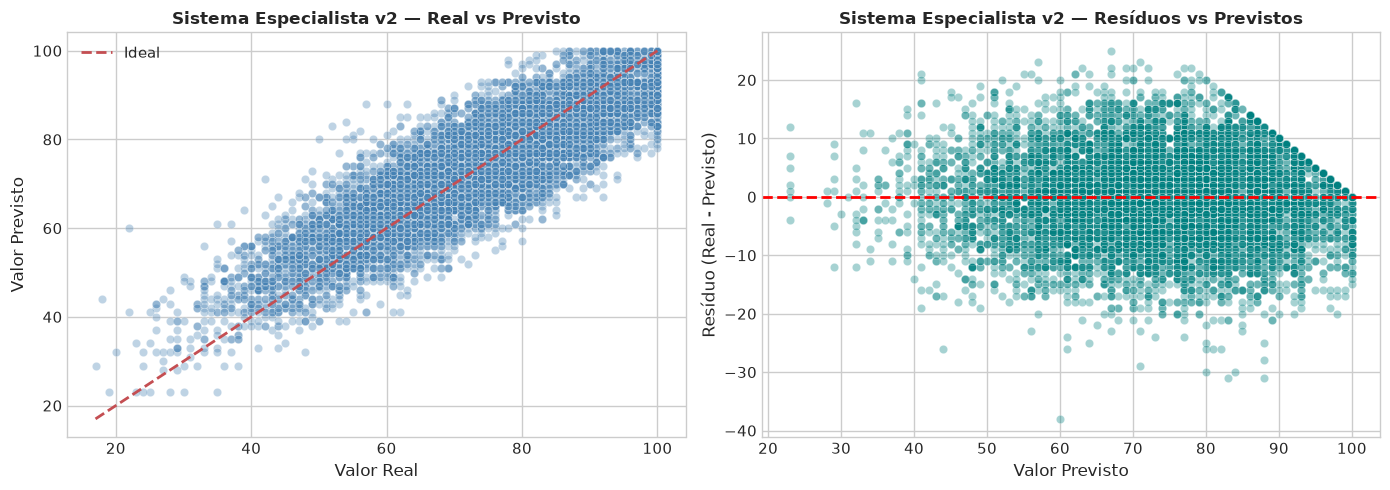

Distribuição das previsões v2 no teste:


,Escore previsto
count,10000.00
mean,74.05
std,13.74
min,23.00
25%,65.00
50%,75.00
75%,84.00
max,100.00


In [12]:
from src.visualization import plotar_residuos

plotar_residuos(
    y_test_r,
    pred_teste_v2,
    titulo="Sistema Especialista v2",
    arquivo_saida=FIGURES_DIR / "residuos_especialista.png",
)
plt.show()

print("Distribuição das previsões v2 no teste:")
display(pd.Series(pred_teste_v2).describe().round(2).to_frame("Escore previsto"))

### 3.5 Inferência de pontuação para um registro

O motor de pontuação devolve o escore final e quais regras contribuíram. Isso
torna a decisão auditável: é possível mostrar ao paciente exatamente quais
fatores somaram ou subtraíram pontos.

In [13]:
exemplo_r = X_test_r.iloc[0]
resultado_pontos = inferir_pontuacao(
    exemplo_r.to_dict(), REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
)

print("Fatos do registro:")
display(exemplo_r.to_frame("Valor"))
print("\nRegras ativadas:")
display(pd.Series(resultado_pontos["regras_ativadas"], name="Regra").to_frame())
print(f"Escore bruto: {resultado_pontos['pontuacao_bruta']:.1f}")
print(f"Escore final (após limites): {resultado_pontos['conclusao']:.1f}")

Fatos do registro:


,Valor
Fasting_Blood_Sugar,192.9
HbA1c,6.7
Age,54.0
BMI,37.3
Family_History_Diabetes,Yes
Hypertension,Yes
Diet_Quality,Healthy
Physical_Activity_Level,Low



Regras ativadas:


,Regra
0,RG_G_ALTA
1,RG_H_ALTA
2,RG_IMC_OBESO2
3,RG_IDADE_ADULTO
4,RG_HIST_FAMILIAR
5,RG_HIPERTENSAO
6,RG_ATIVIDADE_BAIXA


Escore bruto: 98.0
Escore final (após limites): 98.0


In [14]:
exportar_regras_txt(
    REGRAS_REGRESSAO,
    RULES_DIR / "regras_regressao.txt",
    "Base de conhecimento — Regressão (pontuação aditiva)",
    pontuacao_base=PONTUACAO_BASE,
    limites=LIMITES_PONTUACAO,
)
exportar_regras_txt(
    REGRAS_REGRESSAO_V1,
    RULES_DIR / "regras_regressao_v1.txt",
    "Base de conhecimento — Regressão v1 (medianas)",
)

print((RULES_DIR / "regras_regressao.txt").read_text(encoding="utf-8")[:1200])
print("...")

Base de conhecimento — Regressão (pontuação aditiva)

Pontuação base: 53
Limites do escore: 0.0 a 100.0

[RG_G_BAIXA] Glicemia de jejum normal (< 100 mg/dL)
  Tipo: heuristica
  SE Fasting_Blood_Sugar < 100
  ENTÃO PONTOS = -10

[RG_G_PRE] Glicemia de jejum na faixa de pré-diabetes (100–125 mg/dL)
  Tipo: heuristica
  SE Fasting_Blood_Sugar maior ou igual a 100 e menor que 126
  ENTÃO PONTOS = +0

[RG_G_ALTA] Glicemia de jejum em faixa diagnóstica (>= 126 mg/dL)
  Tipo: heuristica
  SE Fasting_Blood_Sugar >= 126
  ENTÃO PONTOS = +10

[RG_H_BAIXA] HbA1c normal (< 5,7%)
  Tipo: heuristica
  SE HbA1c < 5.7
  ENTÃO PONTOS = -9

[RG_H_PRE] HbA1c na faixa de pré-diabetes (5,7–6,4%)
  Tipo: heuristica
  SE HbA1c maior ou igual a 5.7 e menor que 6.5
  ENTÃO PONTOS = +0

[RG_H_ALTA] HbA1c em faixa diagnóstica (>= 6,5%)
  Tipo: heuristica
  SE HbA1c >= 6.5
  ENTÃO PONTOS = +9

[RG_IMC_BAIXO] IMC abaixo de 25 kg/m²
  Tipo: heuristica
  SE BMI < 25
  ENTÃO PONTOS = -5

[RG_IMC_SOBREPESO] IMC de so

## 4. Medição da inferência (eficiência do sistema especialista)

Para o sistema especialista não há treinamento computacional: o custo
relevante é a inferência. Medimos tempo (30 repetições), vazão, pico de memória
e tamanho do modelo.

In [15]:
medicao_c = medir_inferencia(
    lambda X: aplicar_sistema_especialista(X, REGRAS_CLASSIFICACAO),
    X_test_c,
    n_rep=N_REPETICOES_INFERENCIA,
)
medicao_r = medir_inferencia(
    lambda X: aplicar_sistema_especialista_pontuacao(
        X, REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
    ),
    X_test_r,
    n_rep=N_REPETICOES_INFERENCIA,
)

tamanho_c = medir_tamanho_serializado(REGRAS_CLASSIFICACAO)
tamanho_r = medir_tamanho_serializado(REGRAS_REGRESSAO)
tamanho_txt_c = medir_tamanho_arquivo(RULES_DIR / "regras_classificacao.txt")
tamanho_txt_r = medir_tamanho_arquivo(RULES_DIR / "regras_regressao.txt")

eficiencia_especialista = pd.DataFrame(
    {
        "Classificação": {
            **medicao_c,
            "n_regras": len(REGRAS_CLASSIFICACAO),
            "tamanho_pickle_kib": tamanho_c["tamanho_kib"],
            "tamanho_txt_kib": tamanho_txt_c["tamanho_kib"],
        },
        "Regressão": {
            **medicao_r,
            "n_regras": len(REGRAS_REGRESSAO),
            "tamanho_pickle_kib": tamanho_r["tamanho_kib"],
            "tamanho_txt_kib": tamanho_txt_r["tamanho_kib"],
        },
    }
)
display(eficiencia_especialista.round(4))
eficiencia_especialista.to_csv(
    TABLES_DIR / "eficiencia_especialista.csv", encoding="utf-8"
)

,Classificação,Regressão
n_repeticoes,30.0000,30.0000
tempo_medio_s,0.0658,0.0880
tempo_desvio_s,0.0177,0.0323
tempo_por_amostra_ms,0.0066,0.0088
vazao_amostras_s,151942.8861,113615.5341
pico_memoria_mib,2.0958,2.0958
n_regras,4.0000,19.0000
tamanho_pickle_kib,0.7852,1.9375
tamanho_txt_kib,1.0176,2.5605


O tempo por amostra é da ordem de microssegundos e o modelo ocupa poucos
kilobytes. O pico de
memória inclui o DataFrame de saída (com a lista de regras ativadas), não
apenas a base de regras.

## 5. Esforço humano (cronômetro)

O tempo de elaboração foi registrado em `logs/cronometro_regras.csv`. As
sessões mediram a criação das regras, incluindo tentativas descartadas.

In [17]:
log = ler_cronometro()
display(log[["data", "sessao", "problema", "tempo_total", "numero_regras_criadas", "interrupcoes"]])

resumo_log = resumo_cronometro(log)
display(resumo_log.round(2))
resumo_log.to_csv(TABLES_DIR / "cronometragem_regras.csv", index=False, encoding="utf-8")

,data,sessao,problema,tempo_total,numero_regras_criadas,interrupcoes
0,2026-10-23,1,classificacao,00:48:45,7,0
1,2026-10-25,2,classificacao,01:09:00,0,1
2,2026-10-25,3,classificacao,00:34:42,1,0
3,2026-10-25,4,regressao,01:08:13,4,0


,Problema,Sessões,Regras criadas,Tempo total (min),Tempo médio por sessão (min),Desvio padrão (min),Tempo médio por regra (min)
0,Classificacao,3,8,152.45,50.82,17.24,19.06
1,Regressao,1,4,68.22,68.22,NaN,17.05
